<a href="https://colab.research.google.com/github/sorayanakhbaty/proyek-klsasifikasi-gambar-dg/blob/main/proyek_klasifikasi_gambar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Klasifikasi Gambar : Nature Image Classification
- **Nama:** Soraya Nakhbaty
- **Email:** sorayanakhbaty261104@gmail.com
- **ID Dicoding:** M429D5X1865

## Import Semua Packages/Library yang Digunakan

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Rescaling, Resizing
from tensorflow.keras.callbacks import Callback
import matplotlib.pyplot as plt
import os
import numpy as np
from google.colab import files
from tensorflow.keras.preprocessing import image
import pathlib

In [ ]:
!pip install tensorflowjs

## Data Preparation

In [ ]:
import kagglehub

path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification


### Data Loading

### Data Preprocessing

#### Split Dataset

In [ ]:
base_dir = path
train_dir = os.path.join(base_dir, 'seg_train/seg_train')
test_dir = os.path.join(base_dir, 'seg_test/seg_test')

In [ ]:
print("Contents of train_dir:")
for item in os.listdir(train_dir):
    if os.path.isdir(os.path.join(train_dir, item)):
        print(item)

print("\nContents of test_dir:")
for item in os.listdir(test_dir):
    if os.path.isdir(os.path.join(test_dir, item)):
        print(item)

Contents of train_dir:
mountain
street
buildings
sea
forest
glacier

Contents of test_dir:
mountain
street
buildings
sea
forest
glacier


In [ ]:
IMG_SIZE = 150

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2  # Membagi 20% data untuk validasi
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=32,  # Diubah menjadi 32
    class_mode='categorical',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=32,  # Diubah menjadi 32
    class_mode='categorical',
    subset='validation'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

print("\nKelas yang ditemukan:", train_generator.class_indices)

Found 11230 images belonging to 6 classes.
Found 2804 images belonging to 6 classes.
Found 3000 images belonging to 6 classes.

Kelas yang ditemukan: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


## Modelling

In [ ]:
model = Sequential([

    Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(6, activation='softmax') # 6 kelas sesuai dengan dataset
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001)

In [ ]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,455,686 (13.18 MB)

 Trainable params: 3,455,686 (13.18 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
class MyCallback(Callback):
    def on_epoch_end(self, epoch, logs={}):
        if(logs.get('accuracy') > 0.95 and logs.get('val_accuracy') > 0.95):
            print("\nAkurasi training dan validasi telah mencapai > 95%! Menghentikan training...")
            self.model.stop_training = True

# Inisialisasi callback
custom_callback = MyCallback()

history = model.fit(
    train_generator,
    epochs=50,
    validation_data=validation_generator,
    callbacks=[custom_callback],
    verbose=1
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 189s 519ms/step - accuracy: 0.4443 - loss: 1.3594 - val_accuracy: 0.6437 - val_loss: 0.9405
Epoch 2/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 94s 268ms/step - accuracy: 0.6156 - loss: 0.9974 - val_accuracy: 0.6751 - val_loss: 0.8852
Epoch 3/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 94s 268ms/step - accuracy: 0.6797 - loss: 0.8595 - val_accuracy: 0.7026 - val_loss: 0.7748
Epoch 4/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 93s 265ms/step - accuracy: 0.7190 - loss: 0.7795 - val_accuracy: 0.6851 - val_loss: 0.8193
Epoch 5/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 94s 269ms/step - accuracy: 0.7360 - loss: 0.7299 - val_accuracy: 0.7407 - val_loss: 0.7012
Epoch 6/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 94s 269ms/step - accuracy: 0.7572 - loss: 0.6847 - val_accuracy: 0.7778 - val_loss: 0.6369
Epoch 7/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 92s 262ms/step - accuracy: 0.7513 - loss: 0.6913 - val_accuracy: 0.7536 - val_loss: 0.6821
Epoch 8/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 94s 267ms/step - accuracy: 0.7595 - loss: 

## Evaluasi dan Visualisasi

In [ ]:
print("\n--- Mengevaluasi model dengan data test ---")
test_loss, test_acc = model.evaluate(test_generator, verbose=2)
print(f"Akurasi pada test set: {test_acc*100:.2f}%")


--- Mengevaluasi model dengan data test ---
94/94 - 22s - 236ms/step - accuracy: 0.8597 - loss: 0.3951
Akurasi pada test set: 85.97%


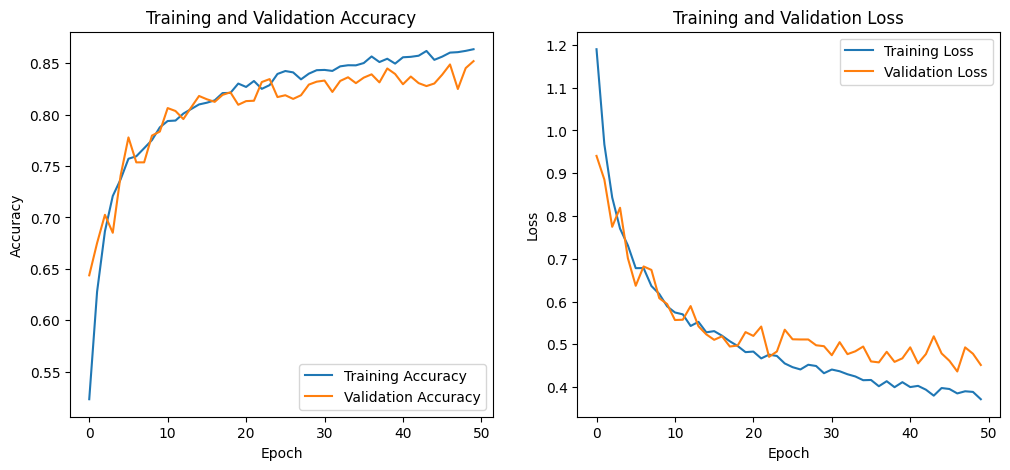

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

# Plot Training and Validation Accuracy
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

# Plot Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.show()

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step


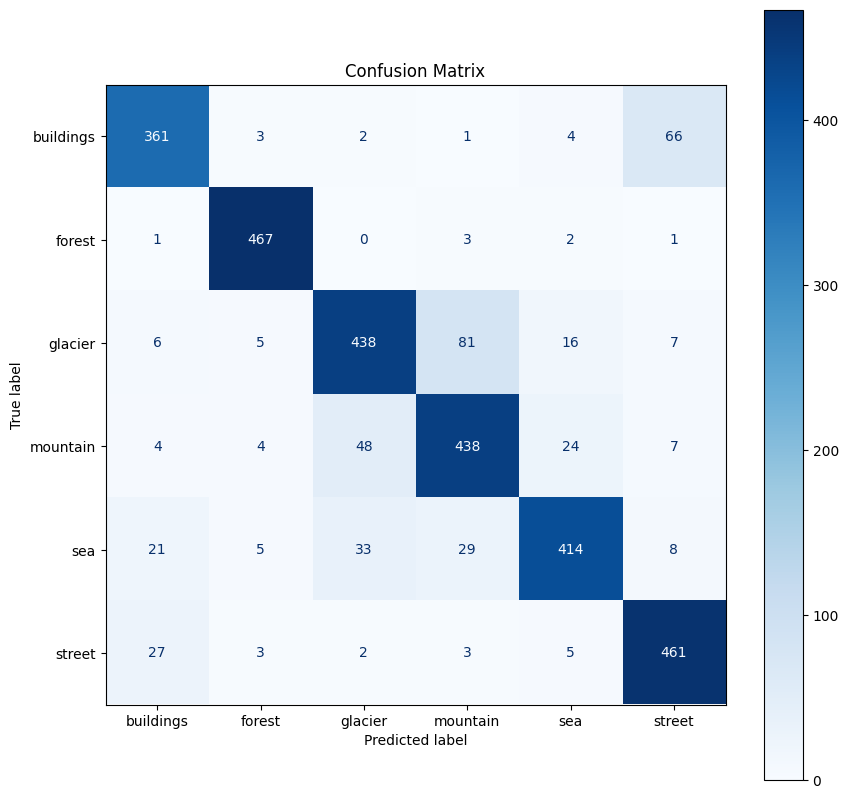

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


test_generator.reset()
true_labels = test_generator.classes
\
predictions = model.predict(test_generator)
predicted_labels = np.argmax(predictions, axis=1)


cm = confusion_matrix(true_labels, predicted_labels)


class_names = list(test_generator.class_indices.keys())

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Confusion Matrix')
plt.show()

## Konversi Model

In [ ]:
# SavedModel
export_dir = 'saved_model/'
model.export(export_dir)
print(f"Model berhasil disimpan dalam format SavedModel di direktori: {export_dir}")

# format TensorFlow Lite (TF-Lite)
converter = tf.lite.TFLiteConverter.from_saved_model(export_dir)
tflite_model = converter.convert()

with open('model.tflokeite', 'wb') as f:
    f.write(tflite_model)
print("Model berhasil disimpan dalam format TF-Lite dengan nama: model.tflite")

# format TensorFlow.js (TFJS)
!tensorflowjs_converter --input_format=tf_saved_model --output_format=tfjs_graph_model {export_dir} tfjs_model
print("Model berhasil disimpan dalam format TFJS di direktori: tfjs_model/")

Saved artifact at 'saved_model/'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  137015442650512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137015442652240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137015442653008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137015442651472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137015442651088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137014403909008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137015442652624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137014403908048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137014403908816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137014403909968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137015442650128: T

## Inference (Optional)

Silakan unggah sebuah gambar pemandangan (misal: gunung, hutan, laut, jalan, bangunan, atau gletser).


Saving images.jpg to images.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 772ms/step


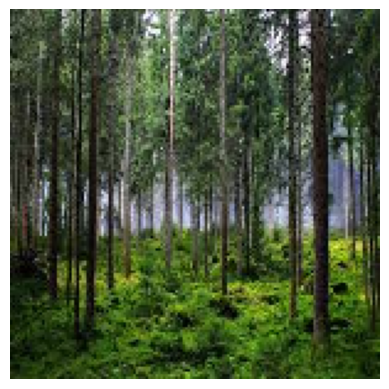

Gambar: images.jpg
Prediksi Kelas: forest
Keyakinan: 100.00%


In [ ]:
class_names = list(train_generator.class_indices.keys())

def predict_image():
    uploaded = files.upload()

    for fn in uploaded.keys():
        path = fn
        img = image.load_img(path, target_size=(IMG_SIZE, IMG_SIZE))
        imgplot = plt.imshow(img)
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        x = x / 255.0  # Normalisasi

        images = np.vstack([x])
        classes = model.predict(images, batch_size=10)
        predicted_class_index = np.argmax(classes[0])
        predicted_class_name = class_names[predicted_class_index]
        confidence = classes[0][predicted_class_index] * 100

        plt.axis('off')
        plt.show()

        print(f"Gambar: {fn}")
        print(f"Prediksi Kelas: {predicted_class_name}")
        print(f"Keyakinan: {confidence:.2f}%")

# Panggil fungsi untuk memulai prediksi
print("Silakan unggah sebuah gambar pemandangan (misal: gunung, hutan, laut, jalan, bangunan, atau gletser).")
predict_image()
